# COMS4060A/7056A – Assignment 2: Geospatial & Time-Series Analysis of NYC Taxi Trips

**Dataset:** NYC TLC taxi trips (Kaggle *nyc-taxi-trip-duration*), `train.csv` only – 1 458 644 trips, 2016-01-01 → 2016-06-30.
**Deadline:** 28 October 2026 · **Total marks:** 63

This single notebook answers every question; each section header carries the question number.
Reasoning that goes in the NeurIPS-style PDF is repeated here in the markdown cells so the two stay in sync.

| Section | Topic | Marks |
|---|---|---|
| 0 | Setup & data loading | – |
| 1 | Data cleaning | 3 |
| 2 | Feature generation | 3 |
| 3 | Time-based analysis | 14 |
| 4 | Location clusters (heatmaps, DBSCAN hotspots) | 12 |
| 5 | Airports | 9 |
| 6 | Dimensionality reduction (PCA / t-SNE / UMAP) | 22 |

> **Progress:** Sections 0–2 are complete. Sections 3–6 are placeholders that will be filled in sequentially.

## 0. Setup & data loading

All random operations use the fixed seed `SEED = 42` for reproducibility.
The loader looks for `train.csv` in a few places and, if it is absent, reads it straight out of the
`nyc-taxi-trip-duration.zip` that sits in the repository (the zip contains a nested `train.zip`).

In [1]:
import os, io, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold"})

FIG_DIR = "figures"            # every figure used in the PDF is also saved here
os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")

# --- constants given in the assignment ---------------------------------------------------
NYC_CENTRE = (40.716662, -74.009899)           # (lat, lon) as given in the brief

In [2]:
def load_train():
    """Load train.csv from disk, or straight out of the nested zip files in the repo."""
    kw = dict(parse_dates=["pickup_datetime", "dropoff_datetime"])
    for p in ["train.csv", "data/train.csv", "/tmp/claude-0/data/raw/train.csv"]:
        if os.path.exists(p):
            return pd.read_csv(p, **kw)
    with zipfile.ZipFile("nyc-taxi-trip-duration.zip") as outer:
        inner = zipfile.ZipFile(io.BytesIO(outer.read("train.zip")))
        with inner.open("train.csv") as f:
            return pd.read_csv(f, **kw)

raw = load_train()
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 1,458,644   Columns: 11


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [3]:
print(raw.dtypes, end="\n\n")
print("Missing values per column:\n", raw.isna().sum().to_string(), sep="")
print("\nDuplicate trip ids:", raw["id"].duplicated().sum())
print("Date range:", raw["pickup_datetime"].min(), "→", raw["pickup_datetime"].max())
# does trip_duration agree with dropoff - pickup?
gap = (raw["dropoff_datetime"] - raw["pickup_datetime"]).dt.total_seconds() - raw["trip_duration"]
print("Rows where trip_duration != dropoff - pickup:", int((gap != 0).sum()))
raw.describe().T

id                               str
vendor_id                      int64
pickup_datetime       datetime64[us]
dropoff_datetime      datetime64[us]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag               str
trip_duration                  int64
dtype: object

Missing values per column:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0



Duplicate trip ids: 0
Date range: 2016-01-01 00:00:17 → 2016-06-30 23:59:39
Rows where trip_duration != dropoff - pickup: 0


,count,mean,min,25%,50%,75%,max,std
vendor_id,1458644.0,1.53495,1.0,1.0,2.0,2.0,2.0,0.498777
pickup_datetime,1458644,2016-04-01 10:10:24.940038,2016-01-01 00:00:17,2016-02-17 16:46:04.250000,2016-04-01 17:19:40,2016-05-15 03:56:08.750000,2016-06-30 23:59:39,NaN
dropoff_datetime,1458644,2016-04-01 10:26:24.432309,2016-01-01 00:03:31,2016-02-17 17:05:32.500000,2016-04-01 17:35:12,2016-05-15 04:10:51.750000,2016-07-01 23:02:03,NaN
passenger_count,1458644.0,1.66453,0.0,1.0,1.0,2.0,9.0,1.314242
pickup_longitude,1458644.0,-73.973486,-121.933342,-73.991867,-73.981743,-73.967331,-61.335529,0.070902
pickup_latitude,1458644.0,40.750921,34.359695,40.737347,40.754101,40.76836,51.881084,0.032881
dropoff_longitude,1458644.0,-73.973416,-121.933304,-73.991325,-73.979752,-73.963013,-61.335529,0.070643
dropoff_latitude,1458644.0,40.7518,32.181141,40.735885,40.754524,40.76981,43.921028,0.035891
trip_duration,1458644.0,959.492273,1.0,397.0,662.0,1075.0,3526282.0,5237.431724


**Initial data audit.** There are no missing values and no duplicate ids, and `trip_duration` is exactly
`dropoff_datetime − pickup_datetime` for every row, so there is no timestamp inconsistency to repair.
The `describe()` table already shows the problem the assignment hints at: coordinates as far away as
longitude −121.9 / latitude 51.9 (not New York), passenger counts of 0 and up to 9, a minimum duration of 1 s
and a maximum of 3 526 282 s (≈ 40 days). The following section quantifies and removes these.

---
## 1. Data Cleaning [3 marks]

**Goal:** identify outliers / impossible records and justify their removal.
We examine five aspects: (a) passenger count, (b) geographic location, (c) trip duration, (d) trip distance, (e) average speed.
Distance is the **great-circle (haversine) distance** between pickup and dropoff (formula supplied in the brief);
speed is `distance / duration`. These two derived columns are also required in Question 2.

> Note on haversine: it is a *lower bound* on the road distance actually driven (streets are not straight lines),
> so the speeds we compute under-estimate real speeds. Thresholds are therefore set generously.

In [4]:
def haversine_np(lon1, lat1, lon2, lat2):
    """Great-circle distance in km between points given in decimal degrees (vectorised)."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

df = raw.copy()
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600.0)
df[["trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.001, .01, .5, .99, .999]).T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
trip_duration,1458644.0,959.492273,5237.431724,1.0,7.0,87.000000,662.000000,3440.000000,85128.357000,3.526282e+06
distance_km,1458644.0,3.438704,4.293840,0.0,0.0,0.138935,2.092403,20.774468,24.751208,1.240130e+03
speed_kmh,1458644.0,14.414153,14.968121,0.0,0.0,1.393366,12.783947,40.719722,54.267879,9.269014e+03


### 1.1 Passenger count

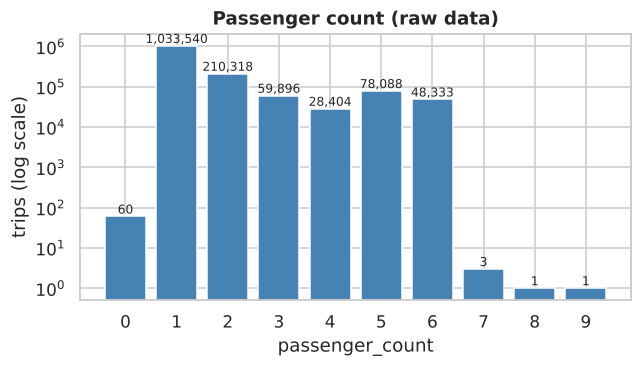

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
vc = raw["passenger_count"].value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color="steelblue")
ax.set_yscale("log"); ax.set_xlabel("passenger_count"); ax.set_ylabel("trips (log scale)")
ax.set_title("Passenger count (raw data)")
for x, v in zip(vc.index.astype(str), vc.values): ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); savefig("q1_passenger_count"); plt.show()

**Reasoning.** Yellow-cab capacity in NYC is 4 passengers (5 for some vehicles; up to 6 for larger vans/minivans, which the data
shows are common: 78 088 trips with 5 and 48 333 with 6 passengers). Counts of **0** (60 trips) have no passenger so
cannot be a real paid trip, and **7, 8, 9** (5 trips in total) exceed the capacity of any taxi. These are data-entry errors
(the field is *driver entered*) so we keep only `1 ≤ passenger_count ≤ 6`.

### 1.2 Geographic outliers

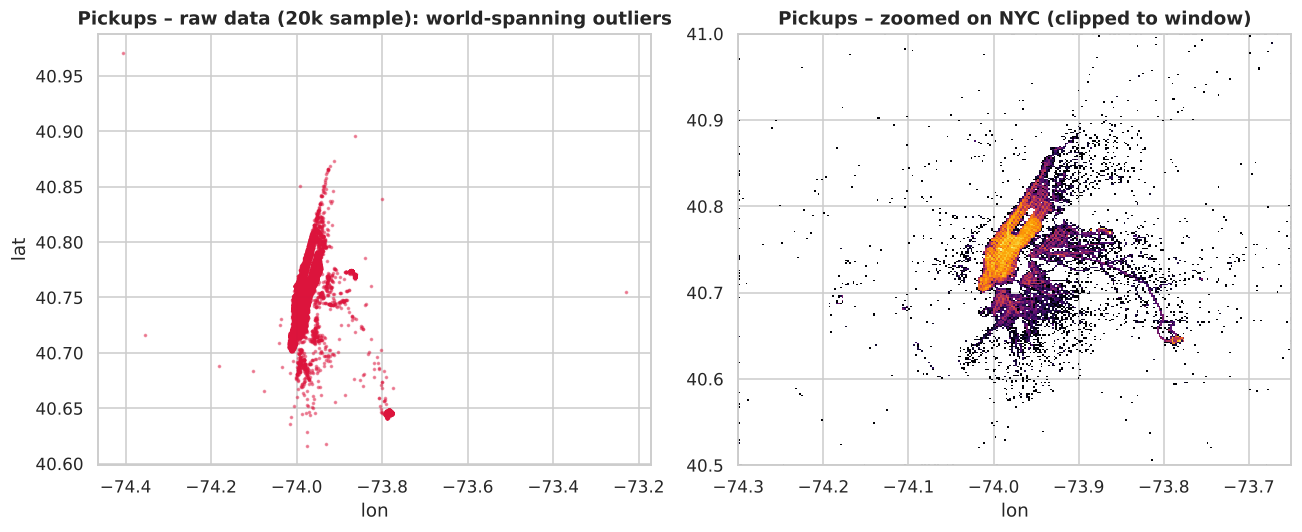

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(raw.pickup_longitude.sample(20000, random_state=SEED), raw.pickup_latitude.sample(20000, random_state=SEED),
                s=2, alpha=.4, color="crimson")
axes[0].set_title("Pickups – raw data (20k sample): world-spanning outliers"); axes[0].set_xlabel("lon"); axes[0].set_ylabel("lat")
h = axes[1].hist2d(raw.pickup_longitude.clip(-74.3, -73.65), raw.pickup_latitude.clip(40.5, 41.0),
                   bins=300, cmap="inferno", norm=plt.matplotlib.colors.LogNorm())
axes[1].set_title("Pickups – zoomed on NYC (clipped to window)"); axes[1].set_xlabel("lon")
plt.tight_layout(); savefig("q1_geo_raw"); plt.show()

In [7]:
# Bounding box that comfortably contains the five boroughs *and* both airports (JFK -73.78, Newark -74.17)
LON_MIN, LON_MAX = -74.30, -73.65
LAT_MIN, LAT_MAX = 40.49, 40.92
in_box = lambda lon, lat: lon.between(LON_MIN, LON_MAX) & lat.between(LAT_MIN, LAT_MAX)
geo_ok = in_box(df.pickup_longitude, df.pickup_latitude) & in_box(df.dropoff_longitude, df.dropoff_latitude)
print(f"Trips with pickup or dropoff outside the NYC window: {(~geo_ok).sum():,} ({(~geo_ok).mean():.3%})")
print("  of which both ends are outside:",
      int((~in_box(df.pickup_longitude, df.pickup_latitude) & ~in_box(df.dropoff_longitude, df.dropoff_latitude)).sum()))

Trips with pickup or dropoff outside the NYC window: 1,096 (0.075%)
  of which both ends are outside: 263


**Reasoning.** The dataset is *New York City* taxi data, yet the raw coordinates include points near longitude −121.9
(the US west coast), latitude 51.9 (Canada) and −61.3 (the Atlantic). These are GPS errors/zero-fixes, not real trips.
We keep trips whose pickup **and** dropoff both lie in the window lon ∈ [−74.30, −73.65], lat ∈ [40.49, 40.92], which
covers all five boroughs plus Newark (−74.17) and JFK (−73.78) airports (needed for Question 5). A point outside this
window cannot be reached by a taxi inside a few-hours trip, and would dominate every spatial analysis (heatmaps, DBSCAN, PCA scaling).

### 1.3 Trip duration

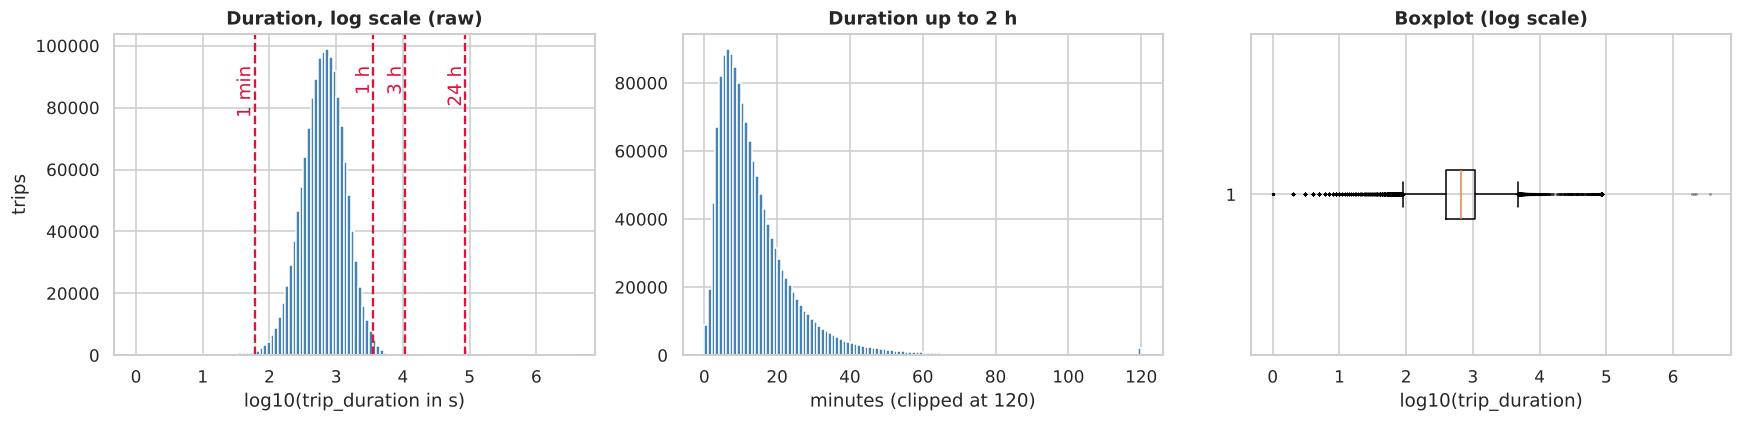

< 60 s : 8,595    < 10 s : 1,984
> 3 h  : 2,112    > 24 h : 4   max = 40.8 days


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(np.log10(raw.trip_duration), bins=120, color="steelblue")
axes[0].set_xlabel("log10(trip_duration in s)"); axes[0].set_ylabel("trips"); axes[0].set_title("Duration, log scale (raw)")
for v, l in [(60, "1 min"), (3600, "1 h"), (10800, "3 h"), (86400, "24 h")]:
    axes[0].axvline(np.log10(v), color="crimson", ls="--"); axes[0].text(np.log10(v), axes[0].get_ylim()[1]*.9, l, rotation=90, color="crimson", va="top", ha="right")
axes[1].hist(raw.trip_duration.clip(upper=7200)/60, bins=120, color="steelblue")
axes[1].set_xlabel("minutes (clipped at 120)"); axes[1].set_title("Duration up to 2 h")
axes[2].boxplot(np.log10(raw.trip_duration), vert=False, flierprops=dict(marker=".", markersize=2, alpha=.3))
axes[2].set_xlabel("log10(trip_duration)"); axes[2].set_title("Boxplot (log scale)")
plt.tight_layout(); savefig("q1_duration_raw"); plt.show()

dur = raw.trip_duration
print(f"< 60 s : {(dur<60).sum():,}    < 10 s : {(dur<10).sum():,}")
print(f"> 3 h  : {(dur>3*3600).sum():,}    > 24 h : {(dur>86400).sum():,}   max = {dur.max()/86400:.1f} days")

**Reasoning.** On a log scale the bulk of trips is a smooth, roughly log-normal bump centred at ≈ 11 min, with a thin
extreme tail on **both** sides:
* **Too short (< 60 s).** A cab cannot meaningfully hail, carry and drop a passenger in under a minute; these are
  accidental meter starts, cancelled rides or driver test records (8 595 trips are < 60 s, 1 984 of them < 10 s).
* **Too long (> 3 h).** Intra-city taxi trips essentially never last longer than a few hours; the tail contains trips of
  up to ≈ 40 days (meter left running/never switched off). 2 112 trips exceed 3 h and 4 exceed 24 h; they they distort every mean and
  every duration scaling. The 3 h cap is conservative: it exceeds the longest realistic NYC–airport journeys in heavy traffic.

### 1.4 Trip distance

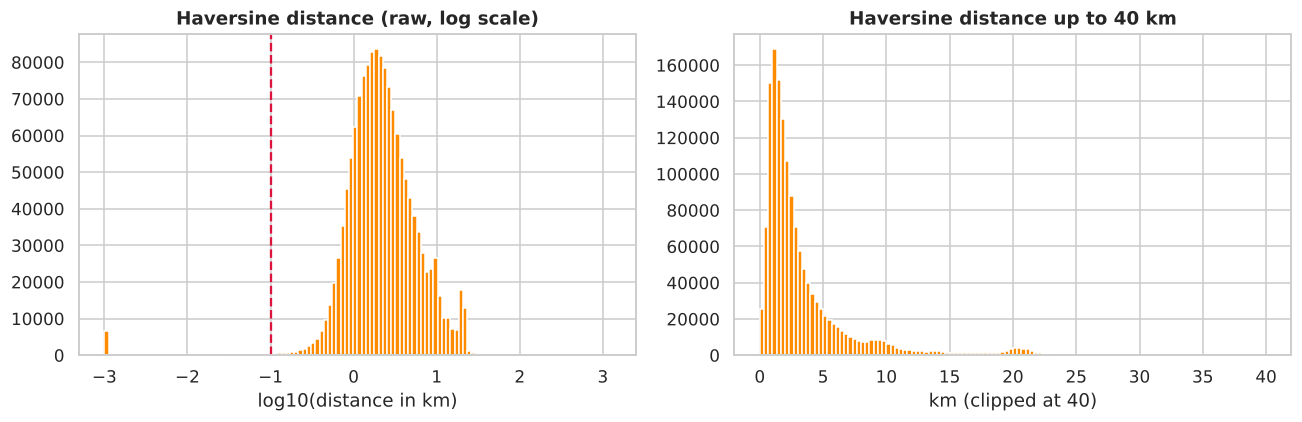

distance == 0 km: 5,897;  < 100 m: 13,319;  > 100 km: 19


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(df.distance_km.clip(lower=1e-3)), bins=120, color="darkorange")
axes[0].set_xlabel("log10(distance in km)"); axes[0].set_title("Haversine distance (raw, log scale)")
axes[0].axvline(np.log10(0.1), color="crimson", ls="--")
axes[1].hist(df.distance_km.clip(upper=40), bins=120, color="darkorange")
axes[1].set_xlabel("km (clipped at 40)"); axes[1].set_title("Haversine distance up to 40 km")
plt.tight_layout(); savefig("q1_distance_raw"); plt.show()
print(f"distance == 0 km: {(df.distance_km == 0).sum():,};  < 100 m: {(df.distance_km < .1).sum():,};  > 100 km: {(df.distance_km > 100).sum():,}")

**Reasoning.** A sizeable spike sits at ≈ 0 km: trips whose pickup and dropoff coordinates are (almost) identical.
Some of these are zero-length because the driver never really drove (cancelled fare) or the GPS failed; for the rest the
speed is meaningless (division by ~0). Trips shorter than **100 m** are below the typical GPS positioning error in
Manhattan's "urban canyon" (≈ 10-50 m), so a 100 m trip is indistinguishable from "didn't move" and cannot represent a
paid taxi fare. On the long side the largest legitimate distance inside our NYC window is below ≈ 50 km
(Newark ↔ the Bronx/Queens is the extreme), so no extra distance upper cap is needed beyond the geographic window and speed filter.

### 1.5 Average speed

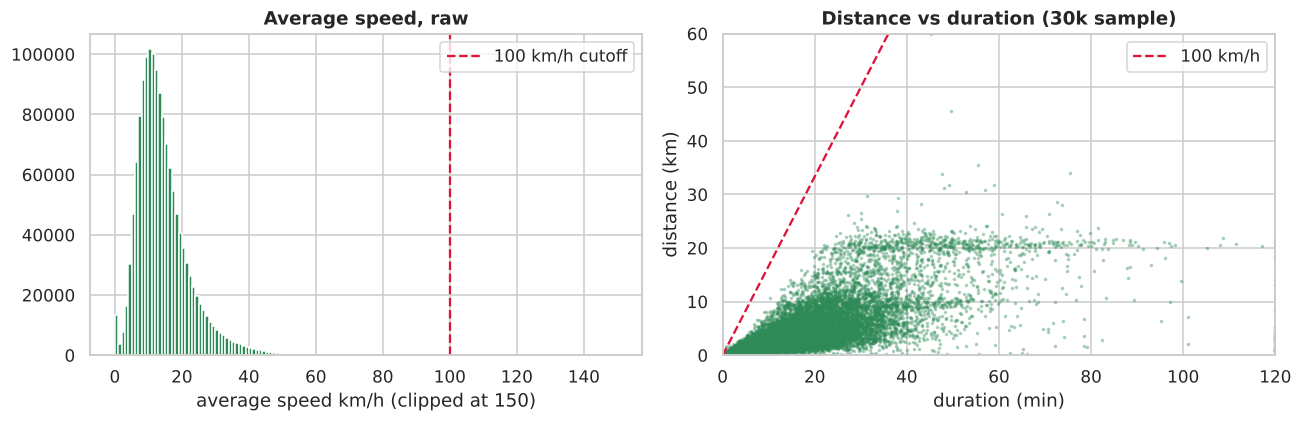

count    1458644.0
mean          14.4
std           15.0
min            0.0
50%           12.8
99%           40.7
99.9%         54.3
max         9269.0
> 100 km/h: 175   > 200 km/h: 68


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df.speed_kmh.clip(upper=150), bins=150, color="seagreen")
axes[0].axvline(100, color="crimson", ls="--", label="100 km/h cutoff"); axes[0].legend()
axes[0].set_xlabel("average speed km/h (clipped at 150)"); axes[0].set_title("Average speed, raw")
axes[1].scatter(df.sample(30000, random_state=SEED).trip_duration.clip(upper=7200)/60,
                df.sample(30000, random_state=SEED).distance_km.clip(upper=60), s=2, alpha=.3, color="seagreen")
for sp, ls in [(100, "--")]:
    x = np.linspace(0, 120, 100); axes[1].plot(x, sp * x / 60, "crimson", ls=ls, label="100 km/h")
axes[1].set_ylim(0, 60); axes[1].set_xlim(0, 120); axes[1].legend()
axes[1].set_xlabel("duration (min)"); axes[1].set_ylabel("distance (km)"); axes[1].set_title("Distance vs duration (30k sample)")
plt.tight_layout(); savefig("q1_speed_raw"); plt.show()
print(df.speed_kmh.describe(percentiles=[.5, .99, .999]).round(1).to_string())
print(f"> 100 km/h: {(df.speed_kmh > 100).sum():,}   > 200 km/h: {(df.speed_kmh > 200).sum():,}")

**Reasoning.** The speed distribution of genuine trips is a right-skewed bell with median ≈ 13 km/h (heavy Manhattan traffic) and a
long right tail. A tail of absurd values (hundreds to thousands of km/h) exists, produced by trips whose recorded
duration is a few seconds but whose coordinates are kilometres apart. The posted speed limits are 25 mph (40 km/h) in the
city and ≤ 65 mph (105 km/h) on highways; as haversine under-estimates road distance, any trip with an *average*
speed over **100 km/h** is physically implausible. We also remove trips below the minimum realistic speed
(see below) because they are trips that were open for a long time with very little movement (waiting taxis, forgotten meters).

3322 trips with average speed < 1 km/h  (walking pace is ~5 km/h)


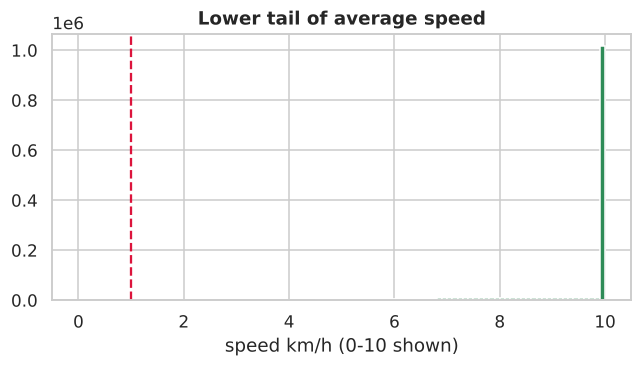

In [11]:
# very slow trips: show the lower tail of speed for trips that moved at least 100 m
slow = df[(df.distance_km >= .1)]
print((slow.speed_kmh < 1).sum(), "trips with average speed < 1 km/h  (walking pace is ~5 km/h)")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(slow.speed_kmh.clip(upper=10), bins=100, color="seagreen"); ax.axvline(1, color="crimson", ls="--")
ax.set_xlabel("speed km/h (0-10 shown)"); ax.set_title("Lower tail of average speed"); plt.tight_layout(); savefig("q1_speed_low"); plt.show()

Trips averaging **< 1 km/h** are slower than walking (~5 km/h) over the entire trip: the vehicle was effectively
stationary with the meter running, so these are not representative trips and are removed.

### 1.6 Applying the filters – cleaning funnel

In [12]:
rules = {
    "passenger_count not in [1, 6]":             ~df.passenger_count.between(1, 6),
    "coordinates outside NYC window":            ~geo_ok,
    "duration < 60 s":                           df.trip_duration < 60,
    "duration > 3 h":                            df.trip_duration > 3 * 3600,
    "distance < 100 m":                          df.distance_km < 0.1,
    "average speed > 100 km/h":                  df.speed_kmh > 100,
    "average speed < 1 km/h":                    df.speed_kmh < 1,
}
rows, remaining = [], pd.Series(True, index=df.index)
for name, bad in rules.items():
    newly = bad & remaining
    rows.append({"rule": name, "flagged_alone": int(bad.sum()), "newly_removed_in_order": int(newly.sum())})
    remaining &= ~bad
funnel = pd.DataFrame(rows)
funnel["flagged_alone_%"] = (funnel.flagged_alone / len(df) * 100).round(3)
print(f"Original: {len(df):,}   Kept: {remaining.sum():,}   Removed: {(~remaining).sum():,} ({(~remaining).mean():.2%})")
funnel

Original: 1,458,644   Kept: 1,438,196   Removed: 20,448 (1.40%)


,rule,flagged_alone,newly_removed_in_order,flagged_alone_%
0,"passenger_count not in [1, 6]",65,65,0.004
1,coordinates outside NYC window,1096,1095,0.075
2,duration < 60 s,8595,8401,0.589
3,duration > 3 h,2112,2104,0.145
4,distance < 100 m,13319,7442,0.913
5,average speed > 100 km/h,175,33,0.012
6,average speed < 1 km/h,13241,1308,0.908


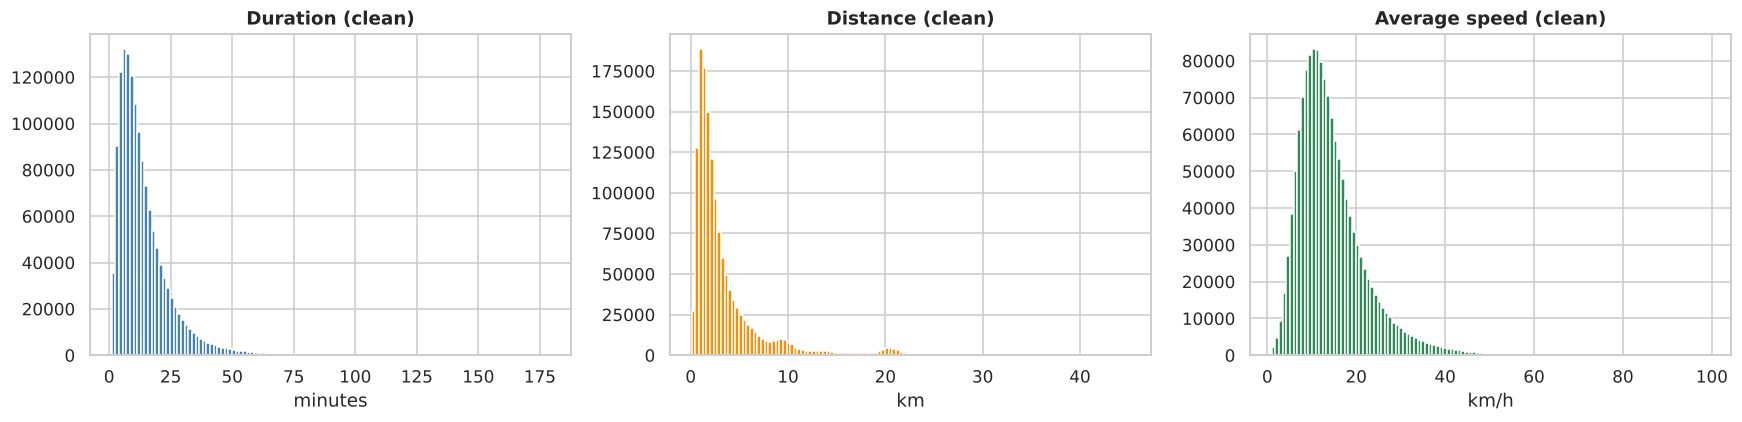

,count,mean,std,min,1%,50%,99%,max
passenger_count,1438196.0,1.67,1.31,1.0,1.00,1.00,6.00,6.00
trip_duration,1438196.0,840.43,653.08,60.0,112.00,665.00,3301.00,10731.00
distance_km,1438196.0,3.46,3.88,0.1,0.39,2.12,20.73,45.08
speed_kmh,1438196.0,14.47,7.59,1.0,3.34,12.85,40.33,99.47


In [13]:
clean = df[remaining].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(clean.trip_duration / 60, bins=120, color="steelblue"); axes[0].set_xlabel("minutes"); axes[0].set_title("Duration (clean)")
axes[1].hist(clean.distance_km, bins=120, color="darkorange"); axes[1].set_xlabel("km"); axes[1].set_title("Distance (clean)")
axes[2].hist(clean.speed_kmh, bins=120, color="seagreen"); axes[2].set_xlabel("km/h"); axes[2].set_title("Average speed (clean)")
plt.tight_layout(); savefig("q1_clean_distributions"); plt.show()

clean[["passenger_count", "trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.01, .5, .99]).T.round(2)

### Summary of Question 1

| Rule | Justification |
|---|---|
| `passenger_count ∉ [1, 6]` | 0 passengers = no fare; 7–9 exceed any taxi's capacity → data-entry errors |
| pickup/dropoff outside lon [−74.30, −73.65], lat [40.49, 40.92] | not in NYC (coordinates in Atlantic, Canada, west coast); window still includes JFK and Newark |
| duration < 60 s | cancelled/accidental meter start, no real journey |
| duration > 3 h | meter left running; up to ≈ 40 days; unrealistic intra-city trip |
| distance < 100 m | below GPS accuracy – trip did not go anywhere; speed undefined |
| speed > 100 km/h | physically impossible for the *average* of a city trip given haversine under-estimates distance |
| speed < 1 km/h | slower than walking over the whole trip → stationary vehicle with meter running |

The filters remove only about 1.4 % of the data (20 448 of 1 458 644 trips) (see funnel), so the cleaned data set is still essentially the full
sample, while mean-based statistics, scalers and distance-based methods (DBSCAN, t-SNE, UMAP) are no longer dominated by errors.
The table above shows how many trips each rule flagged on its own and how many it removed in sequence (rules overlap).

---
## 2. Feature generation [3 marks]

Required: **trip distance**, **day of week**, **average speed**. We add further features that are used in later sections.
Features are built on the *cleaned* data (the order is irrelevant to the result; distance and speed were already
computed above to drive the cleaning, and are re-derived here from scratch so this section stands alone).

In [14]:
feat = clean.copy()

# ---- required features --------------------------------------------------------------------
feat["distance_km"] = haversine_np(feat.pickup_longitude, feat.pickup_latitude,
                                   feat.dropoff_longitude, feat.dropoff_latitude)          # 1. distance of trip
feat["speed_kmh"] = feat["distance_km"] / (feat["trip_duration"] / 3600.0)                  # 3. average speed of trip
feat["day_of_week"] = feat.pickup_datetime.dt.dayofweek                                     # 2. day of week (0=Mon … 6=Sun)
feat["day_name"] = pd.Categorical(feat.pickup_datetime.dt.day_name(),
                                  categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
                                  ordered=True)

# ---- extra features -------------------------------------------------------------------------
feat["pickup_hour"] = feat.pickup_datetime.dt.hour
feat["pickup_date"] = feat.pickup_datetime.dt.normalize()
feat["pickup_month"] = feat.pickup_datetime.dt.month
feat["is_weekend"] = feat.day_of_week >= 5
feat["duration_min"] = feat.trip_duration / 60.0
feat["hour_sin"] = np.sin(2 * np.pi * feat.pickup_hour / 24)      # cyclic hour encoding, used in Q6
feat["hour_cos"] = np.cos(2 * np.pi * feat.pickup_hour / 24)
# Manhattan-style (L1) distance: grid streets mean the real route is closer to |dlat|+|dlon| than to the straight line
feat["manhattan_km"] = (haversine_np(feat.pickup_longitude, feat.pickup_latitude, feat.dropoff_longitude, feat.pickup_latitude)
                      + haversine_np(feat.dropoff_longitude, feat.pickup_latitude, feat.dropoff_longitude, feat.dropoff_latitude))
# initial compass bearing (degrees, 0=north): captures the dominant direction of travel on the Manhattan grid
dlon = np.radians(feat.dropoff_longitude - feat.pickup_longitude)
la1, la2 = np.radians(feat.pickup_latitude), np.radians(feat.dropoff_latitude)
feat["bearing_deg"] = (np.degrees(np.arctan2(np.sin(dlon) * np.cos(la2),
                        np.cos(la1) * np.sin(la2) - np.sin(la1) * np.cos(la2) * np.cos(dlon))) + 360) % 360
# distances to the city centre given in the brief
feat["pickup_dist_centre_km"] = haversine_np(feat.pickup_longitude, feat.pickup_latitude, NYC_CENTRE[1], NYC_CENTRE[0])
feat["dropoff_dist_centre_km"] = haversine_np(feat.dropoff_longitude, feat.dropoff_latitude, NYC_CENTRE[1], NYC_CENTRE[0])

new_cols = ["distance_km", "speed_kmh", "day_of_week", "day_name", "pickup_hour", "pickup_date", "pickup_month", "is_weekend",
            "duration_min", "hour_sin", "hour_cos", "manhattan_km", "bearing_deg", "pickup_dist_centre_km", "dropoff_dist_centre_km"]
print(f"Clean trips: {len(feat):,}   |   new feature columns: {len(new_cols)}")
feat[["pickup_datetime", "trip_duration"] + new_cols].head()

Clean trips: 1,438,196   |   new feature columns: 15


,pickup_datetime,trip_duration,distance_km,speed_kmh,day_of_week,day_name,pickup_hour,pickup_date,pickup_month,is_weekend,duration_min,hour_sin,hour_cos,manhattan_km,bearing_deg,pickup_dist_centre_km,dropoff_dist_centre_km
0,2016-03-14 17:24:55,455,1.497580,11.848984,0,Monday,17,2016-03-14,3,False,7.583333,-0.965926,-0.258819,1.734344,99.970196,6.158130,6.641094
1,2016-06-12 00:43:35,663,1.804374,9.797504,6,Sunday,0,2016-06-12,6,True,11.050000,0.000000,1.000000,2.428980,242.846232,3.476814,1.833676
2,2016-01-19 11:35:24,2124,6.381090,10.815406,1,Tuesday,11,2016-01-19,1,False,35.400000,0.258819,-0.965926,8.198424,200.319835,5.861520,0.825708
3,2016-04-06 19:32:31,429,1.484566,12.457894,2,Wednesday,19,2016-04-06,4,False,7.150000,-0.965926,0.258819,1.660288,187.262300,0.367873,1.122853
4,2016-03-26 13:30:55,435,1.187842,9.830418,5,Saturday,13,2016-03-26,3,True,7.250000,-0.258819,-0.965926,1.198704,179.473585,9.054132,7.952995


In [15]:
feat[["distance_km", "speed_kmh", "duration_min", "manhattan_km", "pickup_dist_centre_km", "dropoff_dist_centre_km"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
distance_km,1438196.0,3.46,3.88,0.10,1.26,2.12,3.90,45.08
speed_kmh,1438196.0,14.47,7.59,1.00,9.23,12.85,17.87,99.47
duration_min,1438196.0,14.01,10.88,1.00,6.70,11.08,17.92,178.85
manhattan_km,1438196.0,4.47,5.16,0.10,1.60,2.72,5.04,61.92
pickup_dist_centre_km,1438196.0,5.52,3.60,0.01,3.10,5.02,7.14,31.21
dropoff_dist_centre_km,1438196.0,5.74,3.55,0.00,3.34,5.25,7.50,33.40


Median Manhattan/straight-line ratio: 1.327


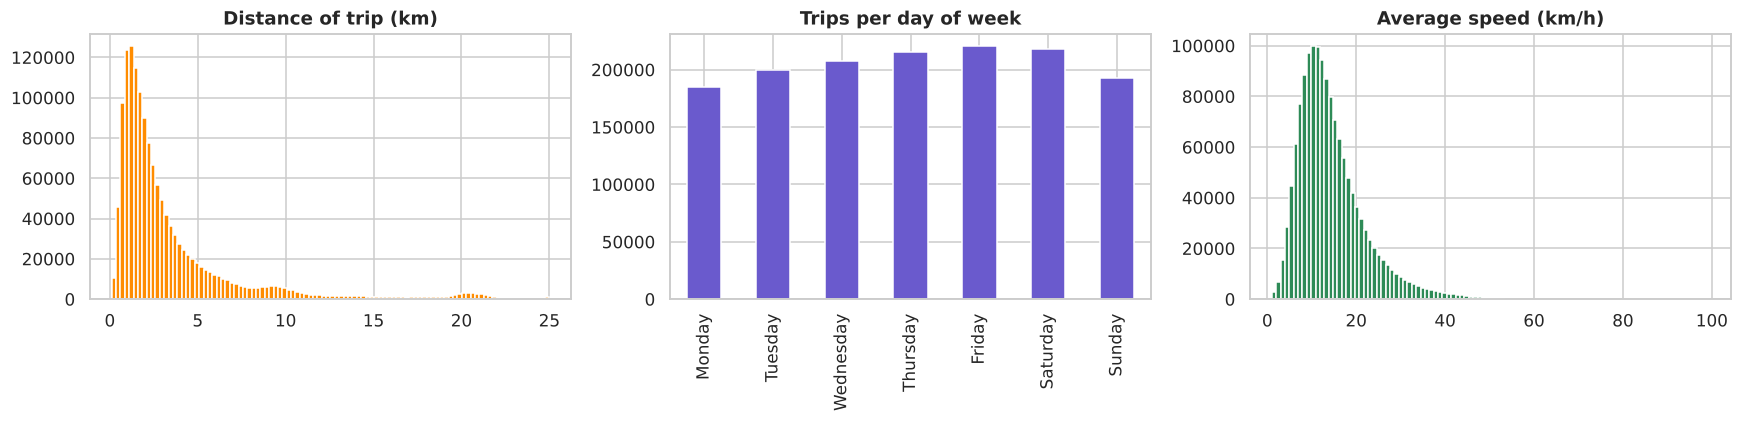

In [16]:
# Sanity checks on the generated features
assert feat.day_of_week.between(0, 6).all() and feat.pickup_hour.between(0, 23).all()
assert (feat.distance_km > 0).all() and (feat.speed_kmh > 0).all()
assert (feat.manhattan_km >= feat.distance_km - 1e-9).all()     # L1 route can never be shorter than the straight line
assert np.allclose(feat.hour_sin**2 + feat.hour_cos**2, 1)
print("Median Manhattan/straight-line ratio:", round((feat.manhattan_km / feat.distance_km).median(), 3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(feat.distance_km.clip(upper=25), bins=100, color="darkorange"); axes[0].set_title("Distance of trip (km)")
feat.day_name.value_counts().sort_index().plot.bar(ax=axes[1], color="slateblue"); axes[1].set_title("Trips per day of week"); axes[1].set_xlabel("")
axes[2].hist(feat.speed_kmh, bins=100, color="seagreen"); axes[2].set_title("Average speed (km/h)")
plt.tight_layout(); savefig("q2_features_overview"); plt.show()

### Summary of Question 2

| Column | Definition | Why it is useful |
|---|---|---|
| `distance_km` **(required)** | haversine distance pickup→dropoff (km) | trip length; used in speed, Q4–Q6 |
| `day_of_week` / `day_name` **(required)** | 0 = Monday … 6 = Sunday, from the pickup time | Q3 weekly patterns |
| `speed_kmh` **(required)** | `distance_km / (trip_duration / 3600)` | Q3.5 speed vs hour; Q6 |
| `pickup_hour`, `pickup_date`, `pickup_month` | calendar components of the pickup time | Q3 time analysis, holiday lookup |
| `is_weekend` | day_of_week ≥ 5 | Q3.3, Q4.1 |
| `duration_min` | `trip_duration` in minutes | readability |
| `hour_sin`, `hour_cos` | cyclic encoding of the hour | Q6 (23:00 is close to 00:00) |
| `manhattan_km` | L1 route distance along the grid | better proxy for road distance than haversine |
| `bearing_deg` | initial compass bearing | direction of travel |
| `pickup_dist_centre_km`, `dropoff_dist_centre_km` | distance to (40.716662, −74.009899) | how central a trip is |

All checks above pass (valid ranges, Manhattan ≥ straight-line, unit-circle hour encoding). The working data frame for the
rest of the notebook is **`feat`**.

---
## 3. Time-based analysis [14 marks]
*(to be completed – next step)*

3.1 Most popular day of week · 3.2 Most popular hour per day · 3.3 Weekdays vs weekends · 3.4 Holidays (St Patrick's Day, Easter, Memorial Day, Valentine's Day, MLK Day – 2016 dates) · 3.5 Speed through the day

---
## 4. Location clusters [12 marks]
*(to be completed)*

4.1 Heatmaps (weekday/weekend, morning/evening) · 4.2 DBSCAN hotspots (Fri 23:00–Sat 02:00, Thu 17:00–20:00)

---
## 5. Airports [9 marks]
*(to be completed)*

Empire State Building → JFK and → Newark: travel time by time of day, with a justified radius.

---
## 6. Dimensionality reduction [22 marks]
*(to be completed)*

6.1 Feature matrix · 6.2 PCA · 6.3 t-SNE · 6.4 UMAP · 6.5 Clustering & cluster profiles · 6.6 Comparison & ARI